# Numerical Exercises 7

### Exerxcise 07.1
In the NSL simulator code we have provided, include tail corrections for potential energy, $U$, and pressure $P$.

### Exercise 07.2

Use the NSL simulator code to <span style="color:red">print out **instantaneous** values of potential energy per particle, $U/N$, along **equilibrated** Monte Carlo $(N,V,T)$ and Molecular Dynamics $(N,V,E)$ simulations</span> of $M=5\times 10^5$ MC steps or MD time steps (where, for MC, the Metropolis acceptance ratio should be fixed approximately to 50% by changing the value of $dt$ that, in the MC case, represent the amplitude of the step in each direction) in the following thermodynamic conditions:
- liquid phase: $\rho^\star = 0.8$, $T^\star = 1.1$ (cut-off radius: $r^\star_c = 2.5$, for MD $dt^\star=0.001$)

Equilibration is needed both with MC and with MD. With MD, you will observe that starting from a perfect crystalline configuration the temperature, $T$, will not conserve its value. Explore and find the starting value of $T$ needed to stabilize, after a certain number of time steps (equilibration time), the average value of $T$ on the desired $T^\star$.
<span style="color:red">Perform your MC and MD simulations by re-starting after such equilibration time.</span>
1. <span style="color:red">Once this data has been produced, compute and make pictures with a python script of the autocorrelation functions of $U/N$ to approximately estimate how large the blocks in your simulations should be.
2. Use the same data to study, with a python script, the estimation of the statistical uncertainties of the expectation value of $U/N$ for different size of the blocks in the data blocking technique, from $L=M/N=10$ to $L=5\times 10^3$, being $N$ the number of blocks. <span style="color:red">Make pictures of these statistical uncertainties as a function of $L$.</span> What you observe in the statistical uncertainties after that the block size is large enough (from the point of view of the data blocking technique)?

### Exercise 07.3

<span style="color:red">Include the calculation of the radial distribution function, $g(r)$, as a function of the radial distance $r$ among particles, with $r \in \left[ 0; L/2\right]$ inside the NSL simulator code</span>: average value of $g(r)$ in each block, final average value of $g(r)$ with statistical uncertainties in a separate file.

### Exercise 07.4

By means of your upgraded NSL simulator code, equilibrate and <span style="color:red">perform MC NVT and MD NVE simulations via a Lennard-Jones model</span> of Argon ($\sigma = 0.34$ nm, $\epsilon/k_B = 120$ K, $m=39.948$ amu) in the following conditions:
- liquid phase: $\rho^\star = 0.8$, $T^\star = 1.1$ (cut-off radius: $r_c = 2.5$)

show in pictures the obtained average values and uncertainties for the potential energy per particle, $U/N$, the pressure $P$ and the radial distribution function $g(r)$ in LJ units ... <span style="color:red"> and compare your MC results for these quantities with those obtained via MD NVE simulations in similar thermodynamic conditions.</span>

## **Solution**
### **07.1**
The approximation of cut-off radius can lead to wrong results, because the Lennard-Jones potential describes a long range interaction. To improve this approximation one can consider the so called **tail corrections**, computed using the **radial distribution function** $g(r)$. In reduced units, these corrections assume the following form[cite: 3]:

$$ \frac{\langle V_{LJ}^* \rangle_{tail}}{N} = 8\pi\rho^* \left[ \frac{1}{9(r_c^*)^9} - \frac{1}{3(r_c^*)^3} \right] $$

$$ \frac{\langle P^* \rangle_{tail}}{3N} = 32\pi\rho^* \left[ \frac{1}{9(r_c^*)^9} - \frac{1}{6(r_c^*)^3} \right] $$

In the `initialize_properties()` method, I implemented the tail corrections:

```cpp

_ptail = 32 * numbers::pi * _rho * (1 / (9 * pow(_r_cut, 9)) - 1 / (6 * pow(_r_cut, 3)));
_vtail = 8.0 / 3.0 * numbers::pi * _rho * (1 / (3 * pow(_r_cut, 9)) - 1 / (pow(_r_cut, 3)));
```
And in `measure()` method:
```cpp
_measurement[_index_pressure] = _rho * (2.0 / 3.0) * kenergy_temp + (_ptail * _npart + 48.0 * virial / 3.0) / _volume;

penergy_temp = _vtail + 4.0 * penergy_temp / double(_npart);
_measurement[_index_penergy] = penergy_temp;
```

### **7.2**
### Equilibration

Before proceeding with the production runs and data blocking, an equilibration stage is essential to ensure that the system relaxes from its initial, non-equilibrium configuration toward thermodynamic equilibrium. 

To achieve this, an *ad hoc* equilibration method (that in the case of Metropolis does an auto-calibration of delta) was implemented within the simulation code. This method performs a dedicated sequence of instantaneous steps:
* For **Molecular Dynamics (MD)** in the microcanonical ensemble ($NVE$), instantaneous quantities are recorded at each time step. The equilibration phase is monitored by observing the relaxation of **kinetic energy** and **temperature**, which exchange energy with the potential degrees of freedom until equipartition is reached and the target temperature stabilizes.
* For **Monte Carlo (MC)** via the $\text{M(RT)}^2$ algorithm in the canonical ensemble ($NVT$), the temperature is inherently fixed by the thermal bath ($\beta$). Therefore, the transient equilibration process is tracked by monitoring the **total energy** (which, in the absence of explicit velocities, corresponds to the instantaneous configurational potential energy per particle) until it plateaus and fluctuates around its equilibrium mean.

In [17]:
import numpy as np
import math   
import matplotlib.pyplot as plt    
from scipy.optimize import curve_fit

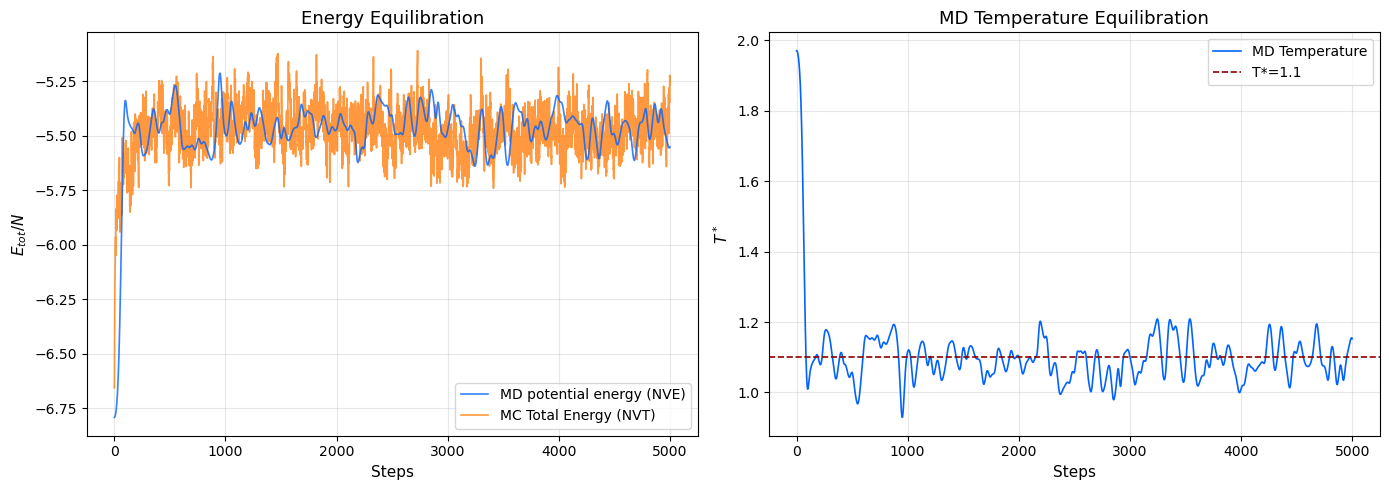

In [5]:
# Percorsi dei file di dati
path_mc_energy = "7.2/OUTPUT/MC/equilibration_energy.dat"
path_md_energy = "7.2/OUTPUT/MD/inst_penergy.dat"
path_md_temp = "7.2/OUTPUT/MD/equilibration_temperature.dat"

data_mc_energy = np.loadtxt(path_mc_energy)
data_md_energy = np.loadtxt(path_md_energy)
data_md_temp = np.loadtxt(path_md_temp)

# Creazione del subplot 1x2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot di sinistra: Equilibrazione Energia (MD vs MC)
ax1.plot(
    data_md_energy[:, 0],
    data_md_energy[:, 1],
    label="MD potential energy (NVE)",
    color="#0363fd",
    alpha=0.8,
    lw=1.2,
    zorder=3,
)
ax1.plot(
    data_mc_energy[:, 0],
    data_mc_energy[:, 1],
    label="MC Total Energy (NVT)",
    color="#ff7f0e",
    alpha=0.8,
    lw=1.2,
    zorder=2,
)
ax1.set_title("Energy Equilibration", fontsize=13)
ax1.set_xlabel("Steps", fontsize=11)
ax1.set_ylabel(r"$E_{tot} / N$", fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=10)

# Subplot di destra: Equilibrazione Temperatura (MD)
ax2.plot(
    data_md_temp[:, 0],
    data_md_temp[:, 1],
    label="MD Temperature",
    color="#0363fd",
    lw=1.2,
)
ax2.set_title("MD Temperature Equilibration", fontsize=13)
ax2.set_xlabel("Steps", fontsize=11)
ax2.set_ylabel(r"$T^*$", fontsize=11)
ax2.axhline(y=1.1, color="darkred", linestyle="--", linewidth=1.2, label="T*=1.1")
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=10)

plt.tight_layout()
plt.show()

The plots display the relaxation dynamics toward thermodynamic equilibrium during the initial phase of the simulation. 

The left plot illustrates the relaxation transient starting from an initial low-energy ordered lattice configuration toward the equilibrium mean value of the potential energy per particle. Molecular Dynamics within the microcanonical ensemble exhibits milder fluctuations due to the strict conservation of total energy, whereas Monte Carlo within the canonical ensemble undergoes larger stochastic fluctuations driven by coupling to the ideal thermal bath.

Regarding the temperature equilibration shown on the right, kinetic energy in the microcanonical ensemble is converted into potential energy as the initial lattice structure melts into a disordered state. Consequently, to reach the desired equilibrium target of $T^* = 1.1$, particle velocities had to be initialized at an elevated temperature of $T^*_{\text{in}} = 1.97$. The trajectory displays a sharp initial drop due to equipartition before stabilizing and oscillating steadily around the target value of $T^* = 1.1$.

Visual inspection confirms that the transient regime decays within the first thousand steps. A duration of **2000 equilibration** steps is therefore fully sufficient to guarantee complete thermalization for both Molecular Dynamics and Monte Carlo prior to starting the production run with block averaging.

### Block Length

In [28]:
def compute_autocorrelation(data, tmax):
    m = len(data)
    tmax = min(tmax, m) 
    var = np.var(data)
    ac = np.zeros(tmax)
    for tau in range(tmax):
        x_t = data[0 : m - tau]
        x_t_tau = data[tau:m]
        product_mean = np.mean(x_t * x_t_tau)
        ac[tau] = (product_mean - np.mean(x_t) * np.mean(x_t_tau)) / var
    return ac

def compute_error_vs_L(data, L_values):
    errors = []
    m = len(data)
    for L in L_values:
        N = m // L
        if N < 2:
            errors.append(np.nan)
            continue
        truncated = data[: N * L]
        block_means = np.mean(truncated.reshape(N, L), axis=1)
        errors.append(np.sqrt(np.var(block_means, ddof=1) / N))
    return np.array(errors)

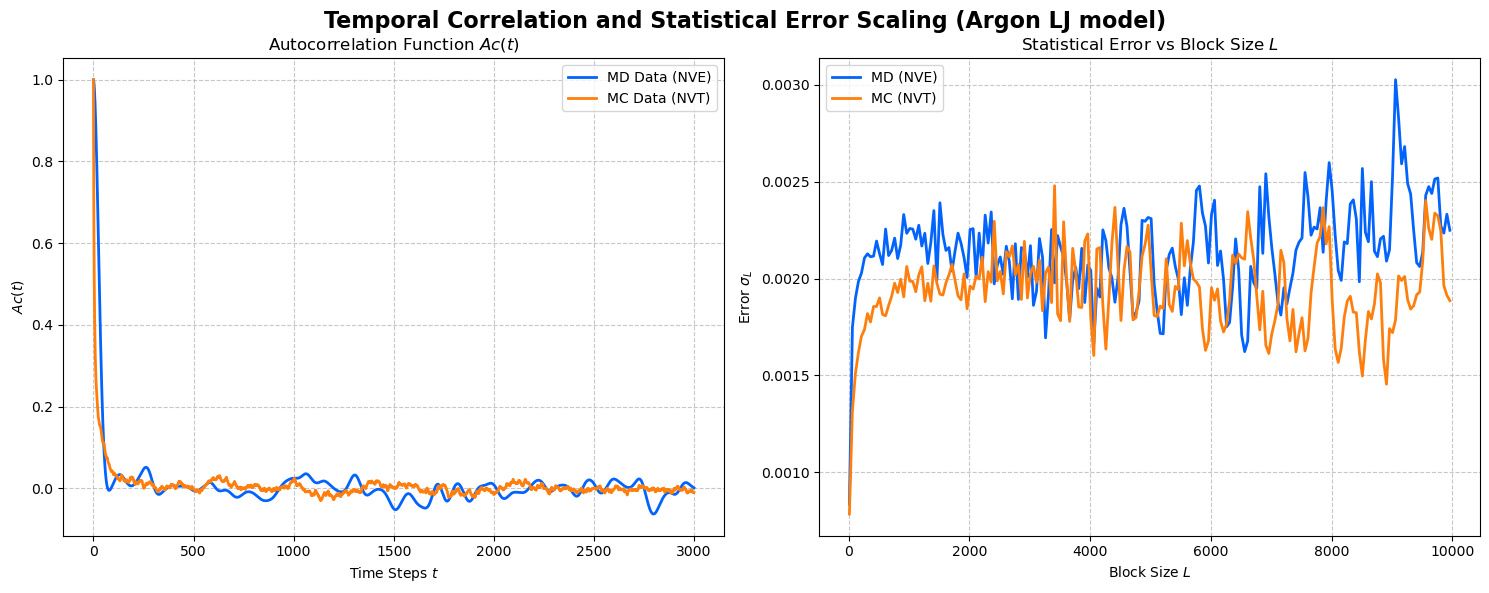

In [30]:
path_mc = "7.2/OUTPUT/MC/"
path_md = "7.2/OUTPUT/MD/"

epot_mc = np.loadtxt(path_mc + "inst_penergy.dat", usecols=(1,))
epot_md = np.loadtxt(path_md + "inst_penergy.dat", usecols=(1,))

tmax = 3000 
L_values = np.arange(10, 10001, 50)

ac_mc = compute_autocorrelation(epot_mc, tmax)
ac_md = compute_autocorrelation(epot_md, tmax)

t_steps = np.arange(len(ac_mc))

err_mc = compute_error_vs_L(epot_mc, L_values)
err_md = compute_error_vs_L(epot_md, L_values)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle("Temporal Correlation and Statistical Error Scaling (Argon LJ model)", fontsize=16, fontweight='bold')

ax1.plot(t_steps, ac_md, label="MD Data (NVE)", color="#0363fd", lw=2)
ax1.plot(t_steps, ac_mc, label="MC Data (NVT)", color="#ff7f0e", lw=2)

ax1.set_title("Autocorrelation Function $Ac(t)$")
ax1.set_xlabel("Time Steps $t$")
ax1.set_ylabel("$Ac(t)$")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.7)

ax2.plot(L_values, err_md, label="MD (NVE)", color="#0363fd", lw=2)
ax2.plot(L_values, err_mc, label="MC (NVT)", color="#ff7f0e", lw=2)

ax2.set_title("Statistical Error vs Block Size $L$")
ax2.set_xlabel("Block Size $L$")
ax2.set_ylabel(r"Error $\sigma_L$")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()
plt.subplots_adjust(top=0.90)
plt.show()

The analysis of the instantaneous potential energy confirms that a block size of $L = 2000$ steps is an excellent and safe choice for both MC and MD simulations. 

* **Autocorrelation:** The temporal correlation function $Ac(t)$ decays to zero rapidly, well within the first 500 steps. 
* **Statistical Error:** The error $\sigma_L$ steeply increases and reaches a stable saturation plateau around $L \approx 1000 - 2000$. The fluctuations observed for much larger block sizes (e.g., $L > 4000$) are strictly a statistical artifact caused by the drastically reduced number of available blocks to average over. 

Therefore, blocks of 2000 steps are sufficiently large to bypass correlation while keeping enough blocks for a robust evaluation of the statistical uncertainty.

### **7.3**
### Implementation of the Radial Distribution Function $g(r)$

The calculation of $g(r)$ up to $r = L/2$ is implemented in three main steps inside the NSL simulator:

**1. Histogram Filling (`System::measure`)**
For each pair of particles, if the distance $dr < L/2$, we evaluate the corresponding bin and increment it by 2 (accounting for both $(i,j)$ and $(j,i)$ pairs):
```cpp
if (dr < _halfside.min()) {
  int bin = int(dr / _bin_size);
  if (bin < _n_bins) _measurement(bin + _index_gofr) += 2.0; 
}
```
**2. Block Normalization (`System::averages`)**
At the end of each block, the histogram is normalized dividing by $\rho N \Delta V(r)$, where $\Delta V(r)$ is the exact volume of the spherical shell for the $i$-th bin:
```cpp
double norm = _rho * double(_npart);
double vofr = 4.0 / 3.0 * std::numbers::pi * (pow(r_dx, 3) - pow(r_sx, 3));
_average(_index_gofr + i) /= (norm * vofr);
```
**3. Final Output and Uncertainties (`System::averages`)**
During the very last block, we evaluate the radial distance $r$ at the **center** of each bin and print the final averages along with their statistical errors to `gofr.dat`:

```cpp
if (_measure_gofr && blk == _nblocks) {
  coutf.open(_output_path + "gofr.dat", ios::app); 
  for (int i = 0; i < _n_bins; i++) {
    double r = (i + 0.5) * _bin_size; // Center of the bin
    coutf << setw(12) << r
          << setw(12) << _global_av(_index_gofr + i) / double(blk)
          << setw(12) << this->error(sum_average, sum_ave2, blk) << endl;
  }
  coutf.close();
}
```

### **7.4**


In this exercise, Molecular Dynamics (MD NVE) and Monte Carlo (MC NVT) simulations of the Lennard-Jones Argon liquid phase ($\rho^* = 0.8$, $T^* = 1.1$, $r_c = 2.5$) are compared. Following thermalization and block equilibration, the macroscopic properties (potential energy $U/N$, pressure $P$, and the radial distribution function $g(r)$) are analyzed. 

*Note on Pressure:* To ensure a rigorous thermodynamic comparison, the ideal gas kinetic contribution ($\rho T$) has been explicitly added to the Monte Carlo pressure output, accounting for the configurational-only sampling of the Metropolis algorithm.

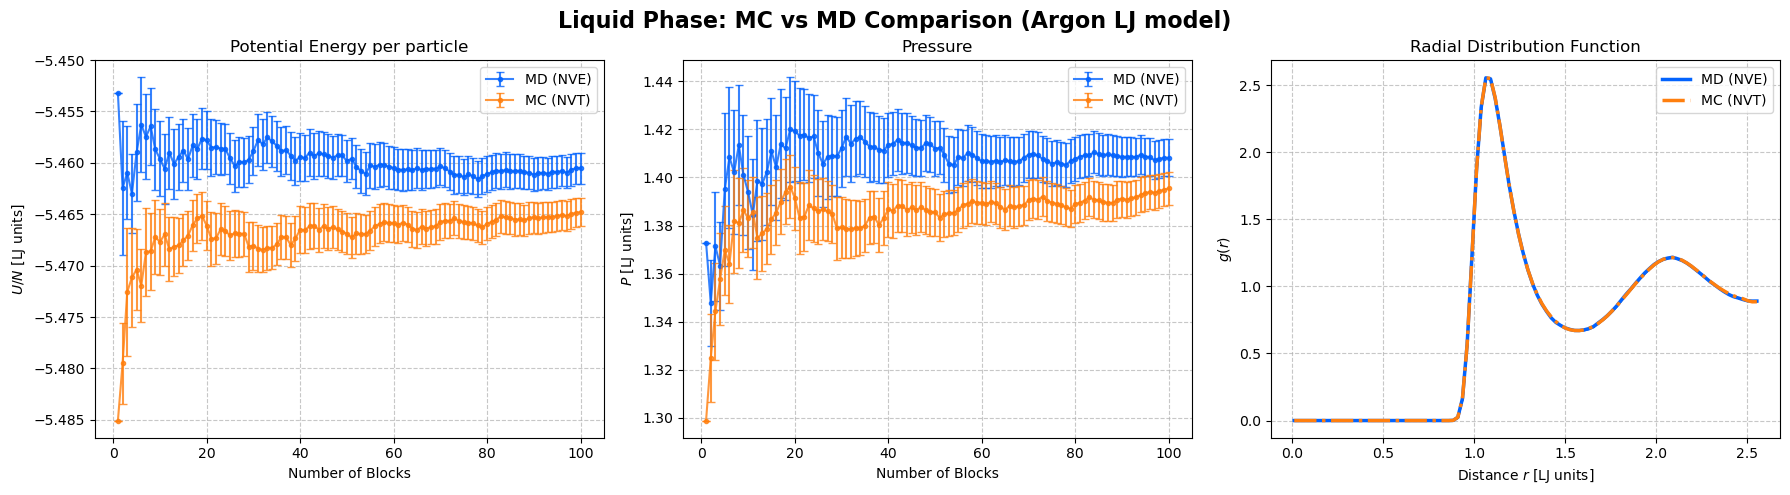

In [31]:
path_mc = "7.4/OUTPUT/MC/"
path_md = "7.4/OUTPUT/MD/"

# Potential Energy
blocks_mc, epot_mc, err_epot_mc = np.loadtxt(path_mc + "potential_energy.dat", usecols=(0, 2, 3), unpack=True)
blocks_md, epot_md, err_epot_md = np.loadtxt(path_md + "potential_energy.dat", usecols=(0, 2, 3), unpack=True)

# Pressure
_, pres_mc, err_pres_mc = np.loadtxt(path_mc + "pressure.dat", usecols=(0, 2, 3), unpack=True)
_, pres_md, err_pres_md = np.loadtxt(path_md + "pressure.dat", usecols=(0, 2, 3), unpack=True)

# Radial Distribution Function g(r)
r_mc, gofr_mc, err_gofr_mc = np.loadtxt(path_mc + "gofr.dat", usecols=(0, 1, 2), unpack=True)
r_md, gofr_md, err_gofr_md = np.loadtxt(path_md + "gofr.dat", usecols=(0, 1, 2), unpack=True)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Liquid Phase: MC vs MD Comparison (Argon LJ model)", fontsize=16, fontweight='bold')

# --- Plot 1: Potential Energy U/N ---
ax1.errorbar(blocks_md, epot_md, yerr=err_epot_md, label="MD (NVE)", color="#0363fd", fmt='.-', capsize=3, alpha=0.8)
ax1.errorbar(blocks_mc, epot_mc, yerr=err_epot_mc, label="MC (NVT)", color="#ff7f0e", fmt='.-', capsize=3, alpha=0.8)
ax1.set_title("Potential Energy per particle")
ax1.set_xlabel("Number of Blocks")
ax1.set_ylabel(r"$U/N$ [LJ units]")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.7)

# --- Plot 2: Pressure P ---
ax2.errorbar(blocks_md, pres_md, yerr=err_pres_md, label="MD (NVE)", color="#0363fd", fmt='.-', capsize=3, alpha=0.8)
ax2.errorbar(blocks_mc, pres_mc, yerr=err_pres_mc, label="MC (NVT)", color="#ff7f0e", fmt='.-', capsize=3, alpha=0.8)
ax2.set_title("Pressure")
ax2.set_xlabel("Number of Blocks")
ax2.set_ylabel(r"$P$ [LJ units]")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.7)

# --- Plot 3: Radial Distribution Function g(r) ---
ax3.plot(r_md, gofr_md, label="MD (NVE)", color="#0363fd", lw=2.5)
ax3.fill_between(r_md, gofr_md - err_gofr_md, gofr_md + err_gofr_md, color="#0363fd", alpha=1)

ax3.plot(r_mc, gofr_mc, label="MC (NVT)", color="#ff7f0e", lw=2.5, linestyle='-.')
ax3.fill_between(r_mc, gofr_mc - err_gofr_mc, gofr_mc + err_gofr_mc, color="#ff7f0e", alpha=0.3)

ax3.set_title("Radial Distribution Function")
ax3.set_xlabel(r"Distance $r$ [LJ units]")
ax3.set_ylabel(r"$g(r)$")
ax3.legend()
ax3.grid(True, linestyle="--", alpha=0.7)

# Adjust layout and show
plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.show()

The comparison between Molecular Dynamics (MD NVE) and Monte Carlo (MC NVT) simulations in the liquid phase ($\rho^* = 0.8$, $T^* = 1.1$) shows excellent consistency across all macroscopic properties. 

* **Potential Energy & Pressure:** Both observables successfully converge through block-averaging, demonstrating proper thermalization and equilibrium state matching between the two ensembles.
* **Radial Distribution Function ($g(r)$):** The structural properties exhibit an exact overlap between MD and MC, confirming that the spatial configurations sampled via the Metropolis algorithm correctly reproduce the liquid-state structure of the Lennard-Jones Argon model.